### MAFAULDA Dataset EDA
Normal vs imbalance subset. All figures save to `../results/eda/`.

In [1]:
import sys, os, glob
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from features import extract_features, FEATURE_ORDER
from dataset import load_mafaulda, MAFAULDA_SAMPLE_RATE

DATA_ROOT = "../data/raw"
RESULTS_DIR = "../results/eda"
BEARING_AXIS = 2  # underhang bearing, radial direction -- closest analog to a radially-mounted ADXL345
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

## Class counts

In [2]:
from collections import Counter

normal_files = sorted(glob.glob(os.path.join(DATA_ROOT, "normal", "*.csv")))
imbalance_files = sorted(glob.glob(os.path.join(DATA_ROOT, "imbalance", "*", "*.csv")))

print(f"normal files: {len(normal_files)}")
print(f"imbalance files: {len(imbalance_files)}")

weights = [os.path.basename(os.path.dirname(f)) for f in imbalance_files]
print("by weight:", dict(Counter(weights)))

normal files: 49
imbalance files: 333
by weight: {'10g': 48, '15g': 48, '20g': 49, '25g': 47, '30g': 47, '35g': 45, '6g': 49}


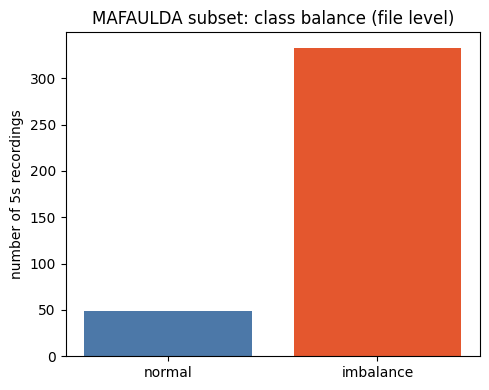

In [3]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["normal", "imbalance"], [len(normal_files), len(imbalance_files)],
       color=["#4C78A8", "#E4572E"])
ax.set_ylabel("number of 5s recordings")
ax.set_title("MAFAULDA subset: class balance (file level)")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "class_balance.png"), dpi=150)
plt.show()

## Raw waveform: normal vs imbalance (20g)
One file from each, first 1s, radial channel.

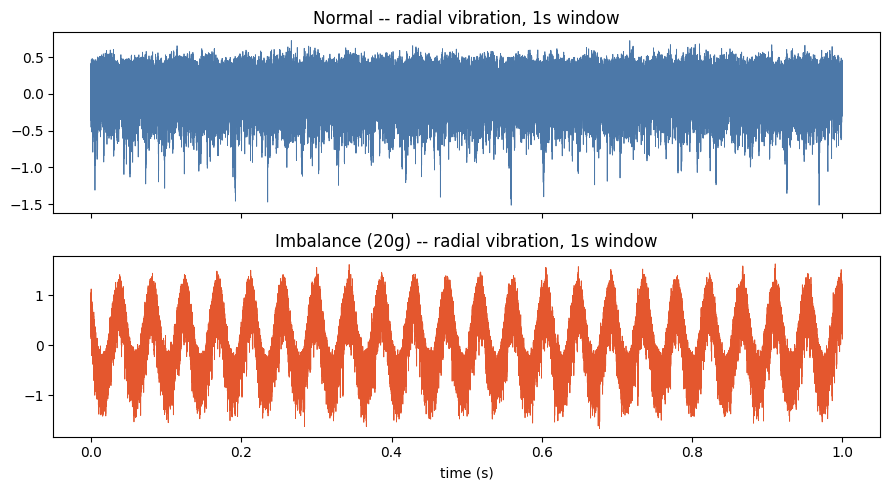

In [4]:
def load_channel(path, axis=BEARING_AXIS, seconds=1.0, sample_rate=MAFAULDA_SAMPLE_RATE):
    data = np.loadtxt(path, delimiter=",", max_rows=int(seconds * sample_rate))
    return data[:, axis]

normal_sample = load_channel(normal_files[10])
imbalance_20g_files = sorted(glob.glob(os.path.join(DATA_ROOT, "imbalance", "20g", "*.csv")))
imbalance_sample = load_channel(imbalance_20g_files[10])

t = np.arange(len(normal_sample)) / MAFAULDA_SAMPLE_RATE

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].plot(t, normal_sample, linewidth=0.6, color="#4C78A8")
axes[0].set_title("Normal -- radial vibration, 1s window")
axes[1].plot(t, imbalance_sample, linewidth=0.6, color="#E4572E")
axes[1].set_title("Imbalance (20g) -- radial vibration, 1s window")
axes[1].set_xlabel("time (s)")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "waveform_comparison.png"), dpi=150)
plt.show()

## FFT: same two files

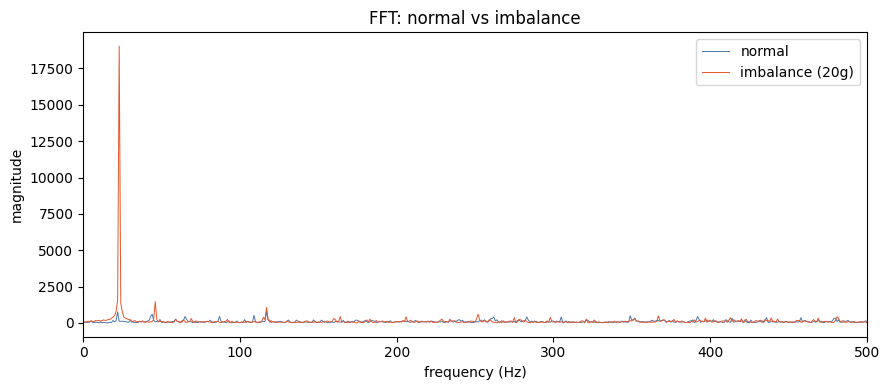

In [5]:
from scipy.fft import rfft, rfftfreq

def plot_fft(signal, sample_rate, ax, label, color):
    spectrum = np.abs(rfft(signal - signal.mean()))
    freqs = rfftfreq(len(signal), d=1.0 / sample_rate)
    ax.plot(freqs, spectrum, linewidth=0.7, color=color, label=label)
    ax.set_xlim(0, 500)

fig, ax = plt.subplots(figsize=(9, 4))
plot_fft(normal_sample, MAFAULDA_SAMPLE_RATE, ax, "normal", "#4C78A8")
plot_fft(imbalance_sample, MAFAULDA_SAMPLE_RATE, ax, "imbalance (20g)", "#E4572E")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("magnitude")
ax.set_title("FFT: normal vs imbalance")
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "fft_comparison.png"), dpi=150)
plt.show()

## Feature distributions across the full subset
Windows the whole normal + imbalance subset (1s windows, via `dataset.load_mafaulda`), extracts the same four features `features.py` will feed the classifier, and saves them for reuse in `train.py`.

In [6]:
windows, labels, sr = load_mafaulda(DATA_ROOT, bearing_axis=BEARING_AXIS, window_s=1.0)
print(f"total windows: {len(windows)}  (normal={int((labels==0).sum())}, imbalance={int((labels==1).sum())})")

feature_rows = []
for w, lbl in zip(windows, labels):
    feat = extract_features(w, sr)
    feat["label"] = "imbalance" if lbl == 1 else "normal"
    feature_rows.append(feat)

df = pd.DataFrame(feature_rows)
df.to_csv("../data/processed/mafaulda_features.csv", index=False)
df.head()

total windows: 1910  (normal=245, imbalance=1665)


,rms,dominant_freq,spectral_energy,kurtosis,label
0,0.306913,117.0,7.795894e+06,-0.773755,normal
1,0.307356,117.0,7.773030e+06,-0.764837,normal
2,0.306421,117.0,8.168650e+06,-0.734071,normal
3,0.307811,117.0,8.297666e+06,-0.653494,normal
4,0.308349,117.0,7.819135e+06,-0.704818,normal


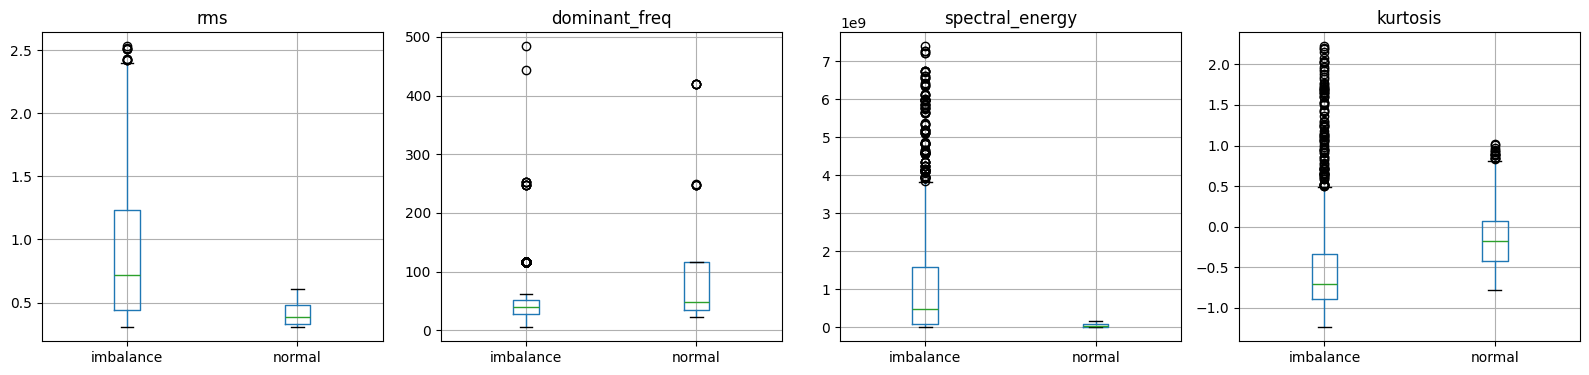

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, feat_name in zip(axes, FEATURE_ORDER):
    df.boxplot(column=feat_name, by="label", ax=ax)
    ax.set_title(feat_name)
    ax.set_xlabel("")
plt.suptitle("")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "feature_distributions.png"), dpi=150)
plt.show()

## Takeaways

- The window-level class balance is more skewed than the file-level count above (5 windows per file). This should be accounted for in train.py, via a stratified split, class weights, or both.
- The boxplots indicate which of the four features separate normal from imbalance most cleanly, providing empirical justification for the feature set.